# 04 – SQL-Datenmodell und Analysen

Die Pipeline schreibt die Daten in eine SQLite-Datenbank im **Sternschema**,
die auch als Datenquelle für das Power-BI-Dashboard dient:

```
             ┌──────────────┐
             │   dim_date   │  1 Zeile je Kalendertag
             │  date (PK)   │  Jahr, Quartal, Monat, Wochentag (DE/EN) …
             └──────┬───────┘
                    │ 1 : n
             ┌──────┴───────┐
             │ energy_data  │  1 Zeile je Stunde (Fakten)
             │ timestamp    │  Preis, Wind, Solar, Last, Features
             │ date (FK)    │
             └──────────────┘
   Views: v_daily_summary, v_monthly_summary
```

Alle Abfragen liegen als eigene Dateien unter `sql/analysis/` und werden in den
Tests automatisch gegen eine Testdatenbank ausgeführt.

In [1]:
import sys
from pathlib import Path

# Projektpaket importierbar machen (alternativ: pip install -e .)
sys.path.insert(0, str(Path.cwd().parent / "src"))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from energy_analytics.config import SQL_DIR
from energy_analytics.database import read_sql_file, run_query, run_sql_file
from energy_analytics.plotting import COLORS, TEXT_MUTED, save, set_style

set_style()


def show(name: str) -> pd.DataFrame:
    """Zeigt die SQL-Abfrage an und gibt das Ergebnis zurück."""
    print(read_sql_file(name))
    return run_sql_file(name)


sorted(p.name for p in (SQL_DIR / "analysis").glob("*.sql"))

['01_data_quality.sql',
 '02_price_kpis_by_year.sql',
 '03_hourly_profile_by_season.sql',
 '04_price_by_renewable_share.sql',
 '05_residual_load_segments.sql',
 '06_negative_price_days.sql',
 '07_monthly_trend.sql',
 '08_weekday_vs_weekend.sql']

In [3]:
run_query("SELECT type, name FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

,type,name
0,table,dim_date
1,table,energy_data
2,view,v_daily_summary
3,view,v_monthly_summary


## 1. Datenqualität (Window Function `LAG`)

In [4]:
show("01_data_quality")

-- Datenqualität: Vollständigkeit, Duplikate und Lücken in der Stundenreihe.
WITH ordered AS (
    SELECT
        (julianday(timestamp) - julianday(LAG(timestamp) OVER (ORDER BY timestamp))) * 24
            AS hours_since_previous
    FROM energy_data
)
SELECT
    (SELECT COUNT(*) FROM energy_data)                         AS total_rows,
    (SELECT COUNT(DISTINCT timestamp) FROM energy_data)        AS distinct_timestamps,
    (SELECT MIN(timestamp_local) FROM energy_data)             AS first_hour_local,
    (SELECT MAX(timestamp_local) FROM energy_data)             AS last_hour_local,
    (SELECT SUM(price IS NULL) + SUM(wind IS NULL) + SUM(solar IS NULL) + SUM(load IS NULL)
       FROM energy_data)                                       AS missing_values,
    SUM(ROUND(hours_since_previous) > 1)                       AS gaps
FROM ordered;



,total_rows,distinct_timestamps,first_hour_local,last_hour_local,missing_values,gaps
0,26304,26304,2023-01-01 00:00:00,2025-12-31 23:00:00,0,0


## 2. Kennzahlen je Jahr

In [5]:
show("02_price_kpis_by_year")

-- Kennzahlen je Jahr: Preisniveau, Extremwerte, negative Preise, Anteil Erneuerbarer.
SELECT
    year,
    ROUND(AVG(price), 2)                                    AS avg_price,
    MIN(price)                                              AS min_price,
    MAX(price)                                              AS max_price,
    SUM(price < 0)                                          AS negative_hours,
    ROUND(100.0 * AVG(price < 0), 2)                        AS negative_share_pct,
    ROUND(100.0 * SUM(renewable_generation) / SUM(load), 1) AS renewable_share_pct,
    -- Veränderung des Durchschnittspreises gegenüber dem Vorjahr
    ROUND(AVG(price) - LAG(AVG(price)) OVER (ORDER BY year), 2) AS avg_price_change_vs_prev_year
FROM energy_data
GROUP BY year
ORDER BY year;



,year,avg_price,min_price,max_price,negative_hours,negative_share_pct,renewable_share_pct,avg_price_change_vs_prev_year
0,2023,95.18,-500.00,524.27,301,3.44,42.2,NaN
1,2024,78.51,-135.45,936.28,457,5.20,42.1,-16.66
2,2025,89.32,-250.32,583.40,576,6.58,43.2,10.81


## 3. Tagesprofil je Jahreszeit (bedingte Aggregation / Pivot)

In [6]:
show("03_hourly_profile_by_season")

-- Tagesprofil des Strompreises (Ortszeit) je Jahreszeit.
-- Zeigt die "Duck Curve": Mittagstief durch Solarstrom, Abendspitze nach Sonnenuntergang.
SELECT
    hour,
    ROUND(AVG(CASE WHEN season = 'Winter'   THEN price END), 2) AS winter,
    ROUND(AVG(CASE WHEN season = 'Frühling' THEN price END), 2) AS fruehling,
    ROUND(AVG(CASE WHEN season = 'Sommer'   THEN price END), 2) AS sommer,
    ROUND(AVG(CASE WHEN season = 'Herbst'   THEN price END), 2) AS herbst,
    ROUND(AVG(price), 2)                                        AS gesamt
FROM energy_data
GROUP BY hour
ORDER BY hour;



,hour,winter,fruehling,sommer,herbst,gesamt
0,0,80.10,84.86,92.89,76.76,83.69
1,1,75.60,79.14,85.55,71.97,78.10
2,2,73.35,77.43,81.35,68.89,75.26
3,3,70.98,76.02,79.16,67.52,73.45
4,4,71.70,77.24,79.68,68.90,74.41
5,5,76.98,83.52,85.23,75.47,80.33
6,6,90.62,98.44,99.67,93.93,95.70
7,7,109.95,107.62,103.81,116.60,109.47
8,8,122.80,98.75,93.10,116.51,107.70
9,9,116.50,78.41,73.79,100.06,92.06


## 4. Merit-Order-Effekt: Preis nach EE-Anteil

In [7]:
by_share = show("04_price_by_renewable_share")
by_share

-- Merit-Order-Effekt: Wie hängt der Preis vom Anteil erneuerbarer Erzeugung ab?
WITH bucketed AS (
    SELECT
        price,
        MIN(CAST(renewable_share_pct / 10 AS INTEGER), 10) * 10 AS share_bucket
    FROM energy_data
)
SELECT
    CASE WHEN share_bucket = 100 THEN '>= 100 %'
         ELSE share_bucket || '-' || (share_bucket + 10) || ' %' END AS renewable_share,
    COUNT(*)                                 AS hours,
    ROUND(AVG(price), 2)                     AS avg_price,
    ROUND(100.0 * AVG(price < 0), 1)         AS negative_share_pct
FROM bucketed
GROUP BY share_bucket
ORDER BY share_bucket;



,renewable_share,hours,avg_price,negative_share_pct
0,0-10 %,2021,146.59,0.0
1,10-20 %,3655,125.10,0.0
2,20-30 %,3690,110.37,0.0
3,30-40 %,3681,101.96,0.0
4,40-50 %,3590,90.51,0.0
5,50-60 %,3125,76.17,0.3
6,60-70 %,2591,56.85,2.3
7,70-80 %,1825,33.26,8.1
8,80-90 %,1257,8.04,37.9
9,90-100 %,683,-8.87,69.7


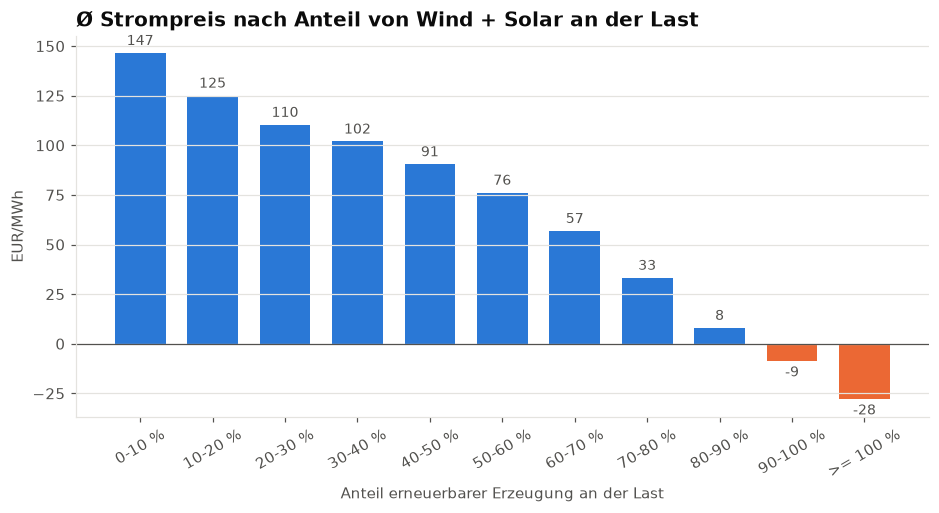

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [COLORS["orange"] if v < 0 else COLORS["blue"] for v in by_share["avg_price"]]
bars = ax.bar(by_share["renewable_share"], by_share["avg_price"], color=colors, width=0.7)
ax.bar_label(bars, fmt="%.0f", padding=3, color=TEXT_MUTED, fontsize=9)
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_title("Ø Strompreis nach Anteil von Wind + Solar an der Last")
ax.set_xlabel("Anteil erneuerbarer Erzeugung an der Last")
ax.set_ylabel("EUR/MWh")
ax.tick_params(axis="x", rotation=30)
save(fig, "price_by_renewable_share")
plt.show()

Mit jedem zusätzlichen 10-%-Punkt EE-Anteil sinkt der Durchschnittspreis um rund
10–25 EUR/MWh. Ab etwa 90 % EE-Anteil ist der Preis im Mittel negativ.

## 5. Preis nach Residuallast-Segment

In [9]:
show("05_residual_load_segments")

-- Preisniveau nach Residuallast (Last minus Wind und Solar).
SELECT
    CASE
        WHEN residual_load < 0     THEN '1: negativ (< 0 GW)'
        WHEN residual_load < 15000 THEN '2: niedrig (0-15 GW)'
        WHEN residual_load < 30000 THEN '3: mittel (15-30 GW)'
        WHEN residual_load < 45000 THEN '4: hoch (30-45 GW)'
        ELSE                            '5: sehr hoch (> 45 GW)'
    END                                      AS residual_load_segment,
    COUNT(*)                                 AS hours,
    ROUND(AVG(price), 2)                     AS avg_price,
    MIN(price)                               AS min_price,
    MAX(price)                               AS max_price,
    ROUND(100.0 * AVG(price < 0), 1)         AS negative_share_pct
FROM energy_data
GROUP BY residual_load_segment
ORDER BY residual_load_segment;



,residual_load_segment,hours,avg_price,min_price,max_price,negative_share_pct
0,1: negativ (< 0 GW),186,-28.03,-500.00,26.3525,89.2
1,2: niedrig (0-15 GW),3618,13.91,-266.92,94.4700,31.3
2,3: mittel (15-30 GW),8835,72.83,-2.09,155.3400,0.4
3,4: hoch (30-45 GW),9844,105.28,35.39,240.0700,0.0
4,5: sehr hoch (> 45 GW),3821,152.03,59.25,936.2800,0.0


## 6. Tage mit den meisten negativen Preisstunden (CTE + `RANK`)

In [10]:
show("06_negative_price_days")

-- Tage mit den meisten Stunden negativer Preise und deren Rahmenbedingungen.
WITH daily AS (
    SELECT
        date(date)                               AS day,
        SUM(price < 0)                           AS negative_hours,
        ROUND(MIN(price), 2)                     AS min_price,
        ROUND(AVG(price), 2)                     AS avg_price,
        ROUND(AVG(solar) / 1000.0, 1)            AS avg_solar_gw,
        ROUND(AVG(wind) / 1000.0, 1)             AS avg_wind_gw,
        MAX(is_weekend)                          AS is_weekend
    FROM energy_data
    GROUP BY date
)
SELECT
    RANK() OVER (ORDER BY negative_hours DESC, min_price) AS rank,
    *
FROM daily
WHERE negative_hours > 0
ORDER BY rank
LIMIT 15;



,rank,day,negative_hours,min_price,avg_price,avg_solar_gw,avg_wind_gw,is_weekend
0,1,2023-12-24,23,-9.07,-3.37,0.5,39.6,1
1,2,2025-10-04,20,-2.60,-0.29,3.5,39.1,1
2,3,2024-07-07,18,-22.37,21.65,11.8,12.7,1
3,4,2025-10-05,17,-4.98,1.73,4.7,38.6,1
4,5,2023-08-08,16,-21.77,12.06,8.9,26.3,0
5,6,2024-08-25,16,-20.01,21.86,8.6,17.7,1
6,7,2024-10-13,16,-15.69,8.11,4.8,34.9,1
7,8,2023-07-02,15,-500.00,-53.87,10.3,22.7,1
8,9,2025-09-16,14,-20.05,19.52,7.7,37.2,0
9,10,2023-01-01,14,-5.40,14.91,1.8,26.9,1


## 7. Monatstrend mit gleitendem Durchschnitt und Vorjahresvergleich

In [11]:
trend = show("07_monthly_trend")
trend.tail(12)

-- Monatlicher Preisverlauf mit gleitendem 3-Monats-Durchschnitt und Vorjahresvergleich.
WITH monthly AS (
    SELECT year, month, AVG(price) AS avg_price
    FROM energy_data
    GROUP BY year, month
)
SELECT
    printf('%04d-%02d', year, month)                                       AS year_month,
    ROUND(avg_price, 2)                                                    AS avg_price,
    ROUND(AVG(avg_price) OVER (
        ORDER BY year, month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS moving_avg_3m,
    ROUND(avg_price - LAG(avg_price, 12) OVER (ORDER BY year, month), 2)  AS change_vs_prev_year
FROM monthly
ORDER BY year, month;



,year_month,avg_price,moving_avg_3m,change_vs_prev_year
24,2025-01,114.14,112.12,37.57
25,2025-02,128.52,116.99,67.19
26,2025-03,94.73,112.46,30.03
27,2025-04,77.94,100.40,15.57
28,2025-05,67.34,80.00,0.13
29,2025-06,63.99,69.75,-8.90
30,2025-07,87.80,73.04,20.10
31,2025-08,76.99,76.26,-5.06
32,2025-09,83.51,82.77,5.20
33,2025-10,84.40,81.63,-1.69


## 8. Werktag vs. Wochenende

In [12]:
show("08_weekday_vs_weekend")

-- Werktag vs. Wochenende: Nachfrage, Solarerzeugung und Preis je Tageshälfte.
SELECT
    CASE WHEN is_weekend THEN 'Wochenende' ELSE 'Werktag' END              AS day_type,
    CASE WHEN hour BETWEEN 8 AND 19 THEN 'Tag (8-20 Uhr)' ELSE 'Nacht' END AS day_part,
    ROUND(AVG(price), 2)            AS avg_price,
    ROUND(AVG(load) / 1000.0, 1)    AS avg_load_gw,
    ROUND(AVG(solar) / 1000.0, 1)   AS avg_solar_gw
FROM energy_data
GROUP BY day_type, day_part
ORDER BY day_type DESC, day_part;



,day_type,day_part,avg_price,avg_load_gw,avg_solar_gw
0,Wochenende,Nacht,80.64,42.9,0.3
1,Wochenende,Tag (8-20 Uhr),56.24,49.7,13.9
2,Werktag,Nacht,95.23,49.6,0.3
3,Werktag,Tag (8-20 Uhr),95.46,61.3,13.5


## Views für Power BI

In [13]:
run_query("SELECT * FROM v_monthly_summary ORDER BY year, month").tail(6)

,year,month,year_month,avg_price,min_price,max_price,negative_price_hours,wind_gwh,solar_gwh,load_gwh,renewable_share_pct
30,2025,7,2025-07,87.80,-2.260,476.1900,12,7441.6,8375.8,37035.8,42.7
31,2025,8,2025-08,76.99,-61.080,283.8900,64,7382.5,9155.9,35373.4,46.8
32,2025,9,2025-09,83.51,-53.400,413.6600,60,11525.1,6166.6,36471.7,48.5
33,2025,10,2025-10,84.40,-4.980,407.2050,51,16528.1,3540.0,40475.5,49.6
34,2025,11,2025-11,101.88,4.925,373.3125,0,12418.2,2133.7,41470.3,35.1
35,2025,12,2025-12,93.47,3.515,308.3500,0,15773.4,1443.0,42304.5,40.7
